# E-commerce Sales Analysis with SQL

This notebook works through a full year of transactions from a UK-based online retailer that sells gift and
home-ware items to consumers and wholesalers in 38 countries.
The questions are the ones an e-commerce team asks every week:
- Where does revenue come from?
- Who are the best customers?
- Do new customers come back?
- What is being cancelled?

All analysis is done in **SQL** (SQLite with CTEs and window functions). Python is used only to load the data and draw charts.

**Data:** [Online Retail dataset](https://archive.ics.uci.edu/dataset/352/online+retail), UCI Machine Learning Repository (CC BY 4.0).
It has 541,909 invoice lines from 1 Dec 2010 to 9 Dec 2011, and customer IDs are already anonymised.
The notebook downloads the data on the first run, and none of it is stored in this repository.

**Contents**
1. Load & data-quality audit
2. Cleaning rules (as SQL)
3. Revenue trend & order value
4. Products & countries
5. When do people buy? (weekday × hour)
6. Customer concentration (Pareto)
7. Cohort retention
8. RFM segmentation
9. Cancellations
10. Findings

In [1]:
import io
import sqlite3
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.2f}".format

URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
cache = Path("data/online_retail.csv")
if not cache.exists():
    cache.parent.mkdir(exist_ok=True)
    with urllib.request.urlopen(URL) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
    pd.read_excel(z.open("Online Retail.xlsx"), dtype={"InvoiceNo": str, "StockCode": str}).to_csv(cache, index=False)

raw = pd.read_csv(cache, dtype={"InvoiceNo": str, "StockCode": str, "CustomerID": "Int64"}, parse_dates=["InvoiceDate"])
con = sqlite3.connect(":memory:")
raw.assign(InvoiceDate=raw.InvoiceDate.dt.strftime("%Y-%m-%d %H:%M:%S")).to_sql("raw", con, index=False)

def q(sql: str) -> pd.DataFrame:
    return pd.read_sql_query(sql, con)

print(f"{len(raw):,} rows loaded into SQLite table `raw`")
q("SELECT * FROM raw LIMIT 5")

541,909 rows loaded into SQLite table `raw`


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## 1. Data-quality audit

In [2]:
q('''
SELECT
  COUNT(*)                                                AS rows_total,
  SUM(CustomerID IS NULL)                                 AS missing_customer,
  SUM(InvoiceNo LIKE 'C%')                                AS cancellation_lines,
  SUM(Quantity <= 0 AND InvoiceNo NOT LIKE 'C%')          AS non_positive_qty_not_cancel,
  SUM(UnitPrice <= 0)                                     AS zero_or_negative_price,
  SUM(StockCode IN ('POST','DOT','M','BANK CHARGES','AMAZONFEE','CRUK','D','S','B','PADS'))
                                                          AS non_product_codes,
  COUNT(*) - COUNT(DISTINCT InvoiceNo || StockCode || Quantity || InvoiceDate) AS exact_duplicates
FROM raw
''').T.rename(columns={0: "count"})

,count
rows_total,541909
missing_customer,135080
cancellation_lines,9288
non_positive_qty_not_cancel,1336
zero_or_negative_price,2517
non_product_codes,2771
exact_duplicates,5429


Problems found in the raw data:
- About a quarter of the lines have **no customer ID** (guest checkouts). They still count as revenue, but they cannot be used for customer analysis.
- Cancellations are invoices starting with `C`, and they carry negative quantities.
- Some lines have a zero price or are stock adjustments.
- Some lines are postage, fees or manual entries rather than products.
- There are a few thousand exact duplicate lines.

## 2. Cleaning rules

In [3]:
con.executescript('''
DROP TABLE IF EXISTS sales;
CREATE TABLE sales AS
SELECT DISTINCT
  InvoiceNo, StockCode, TRIM(Description) AS Description, Quantity, UnitPrice,
  Quantity * UnitPrice AS revenue, InvoiceDate,
  substr(InvoiceDate, 1, 7) AS month, CustomerID, Country
FROM raw
WHERE InvoiceNo NOT LIKE 'C%'
  AND Quantity > 0 AND UnitPrice > 0
  AND StockCode NOT IN ('POST','DOT','M','BANK CHARGES','AMAZONFEE','CRUK','D','S','B','PADS');

DROP TABLE IF EXISTS cancels;
CREATE TABLE cancels AS
SELECT InvoiceNo, StockCode, Description, -Quantity AS qty, UnitPrice, -Quantity * UnitPrice AS value,
       InvoiceDate, CustomerID, Country
FROM raw WHERE InvoiceNo LIKE 'C%' AND StockCode NOT IN ('POST','DOT','M','BANK CHARGES','AMAZONFEE','CRUK','D','S','B','PADS');
''')
q('''
SELECT COUNT(*) AS lines, COUNT(DISTINCT InvoiceNo) AS orders, COUNT(DISTINCT CustomerID) AS customers,
       COUNT(DISTINCT StockCode) AS products, COUNT(DISTINCT Country) AS countries,
       ROUND(SUM(revenue)) AS revenue_gbp
FROM sales
''')

,lines,orders,customers,products,countries,revenue_gbp
0,522710,19776,4334,3914,38,"10,254,959.00"


## 3. Revenue trend & order value

In [4]:
monthly = q('''
WITH orders AS (
  SELECT InvoiceNo, month, SUM(revenue) AS order_value, CustomerID
  FROM sales GROUP BY InvoiceNo
)
SELECT month,
       ROUND(SUM(order_value))            AS revenue,
       COUNT(*)                            AS orders,
       COUNT(DISTINCT CustomerID)          AS customers,
       ROUND(AVG(order_value), 1)          AS avg_order_value,
       ROUND(100.0 * (SUM(order_value) - LAG(SUM(order_value)) OVER (ORDER BY month))
             / LAG(SUM(order_value)) OVER (ORDER BY month), 1) AS revenue_mom_pct
FROM orders GROUP BY month ORDER BY month
''')
monthly

,month,revenue,orders,customers,avg_order_value,revenue_mom_pct
0,2010-12,"776,318.00",1551,884,500.50,NaN
1,2011-01,"670,639.00",1081,739,620.40,-13.60
2,2011-02,"508,082.00",1093,757,464.90,-24.20
3,2011-03,"690,592.00",1440,973,479.60,35.90
4,2011-04,"515,870.00",1235,853,417.70,-25.30
5,2011-05,"740,472.00",1668,1054,443.90,43.50
6,2011-06,"738,234.00",1525,990,484.10,-0.30
7,2011-07,"688,803.00",1452,946,474.40,-6.70
8,2011-08,"724,708.00",1340,933,540.80,5.20
9,2011-09,"1,029,245.00",1819,1259,565.80,42.00


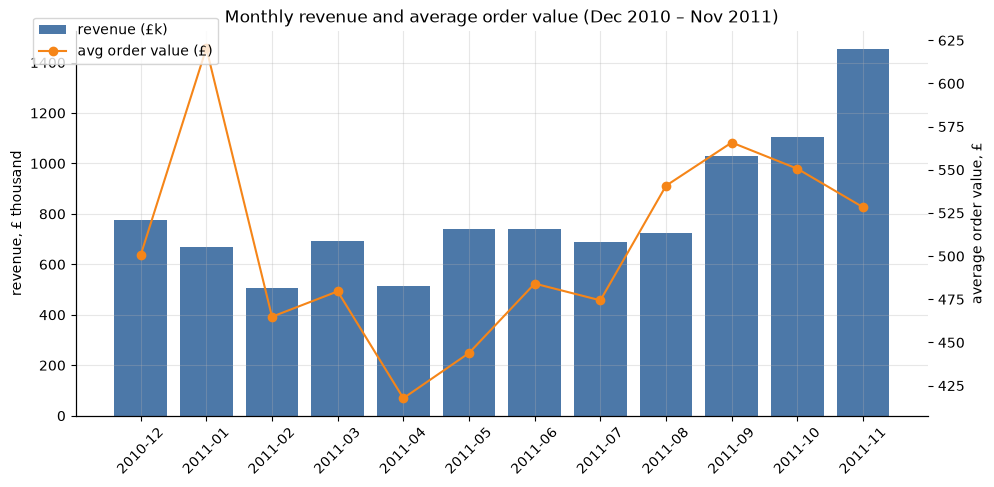

In [5]:
m = monthly[monthly.month < "2011-12"]   # Dec 2011 has only 9 days
fig, ax1 = plt.subplots()
ax1.bar(m.month, m.revenue / 1e3, color="#4C78A8", label="revenue (£k)")
ax1.set_ylabel("revenue, £ thousand"); ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx(); ax2.plot(m.month, m.avg_order_value, color="#F58518", marker="o", label="avg order value (£)")
ax2.set_ylabel("average order value, £"); ax2.grid(False)
ax1.set_title("Monthly revenue and average order value (Dec 2010 – Nov 2011)")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92)); plt.show()

## 4. Products & countries

In [6]:
q('''
SELECT StockCode, MAX(Description) AS product, SUM(Quantity) AS units, ROUND(SUM(revenue)) AS revenue,
       COUNT(DISTINCT CustomerID) AS buyers,
       ROUND(100.0 * SUM(revenue) / (SELECT SUM(revenue) FROM sales), 2) AS pct_of_revenue
FROM sales GROUP BY StockCode ORDER BY revenue DESC LIMIT 10
''')

,StockCode,product,units,revenue,buyers,pct_of_revenue
0,22423,REGENCY CAKESTAND 3 TIER,13851,"174,157.00",881,1.70
1,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,"168,470.00",1,1.64
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,"104,463.00",856,1.02
3,47566,PARTY BUNTING,18283,"99,445.00",708,0.97
4,85099B,JUMBO BAG RED RETROSPOT,48371,"94,160.00",635,0.92
5,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,"81,701.00",138,0.80
6,23084,RABBIT NIGHT LIGHT,30739,"66,870.00",450,0.65
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,19329,"64,876.00",613,0.63
8,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,"58,928.00",678,0.57
9,79321,CHILLI LIGHTS,10302,"54,096.00",205,0.53


In [7]:
countries = q('''
SELECT Country, COUNT(DISTINCT InvoiceNo) AS orders, COUNT(DISTINCT CustomerID) AS customers,
       ROUND(SUM(revenue)) AS revenue,
       ROUND(SUM(revenue) / COUNT(DISTINCT InvoiceNo), 1) AS avg_order_value,
       ROUND(100.0 * SUM(revenue) / (SELECT SUM(revenue) FROM sales), 1) AS pct_of_revenue
FROM sales GROUP BY Country ORDER BY revenue DESC
''')
countries.head(10)

,Country,orders,customers,revenue,avg_order_value,pct_of_revenue
0,United Kingdom,17901,3916,"8,726,607.00",487.50,85.10
1,Netherlands,93,9,"283,889.00","3,052.60",2.80
2,EIRE,284,3,"276,091.00",972.20,2.70
3,Germany,443,94,"205,381.00",463.60,2.00
4,France,383,87,"184,679.00",482.20,1.80
5,Australia,56,9,"138,104.00","2,466.10",1.30
6,Spain,88,30,"55,707.00",633.00,0.50
7,Switzerland,50,21,"53,066.00","1,061.30",0.50
8,Japan,19,8,"37,416.00","1,969.30",0.40
9,Belgium,98,25,"36,927.00",376.80,0.40


## 5. When do people buy?

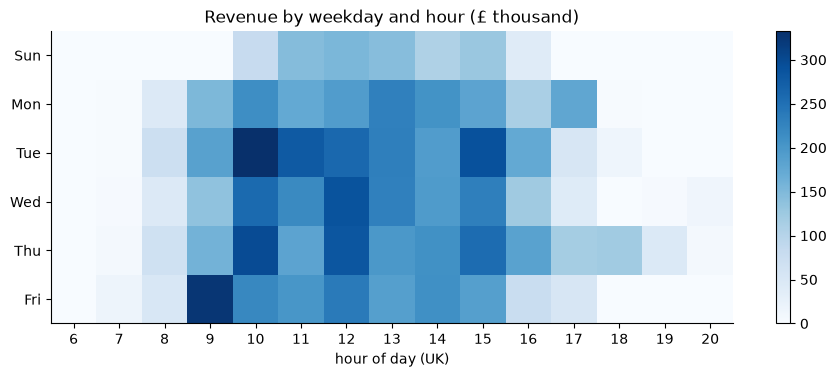

In [8]:
heat = q('''
SELECT CAST(strftime('%w', InvoiceDate) AS INT) AS weekday, CAST(strftime('%H', InvoiceDate) AS INT) AS hour,
       ROUND(SUM(revenue)) AS revenue
FROM sales GROUP BY weekday, hour
''').pivot(index="weekday", columns="hour", values="revenue").fillna(0)
heat.index = heat.index.map({0: "Sun", 1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat"})
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(heat / 1e3, aspect="auto", cmap="Blues")
ax.set_xticks(range(len(heat.columns)), heat.columns); ax.set_yticks(range(len(heat.index)), heat.index)
ax.set_xlabel("hour of day (UK)"); ax.set_title("Revenue by weekday and hour (£ thousand)"); ax.grid(False)
fig.colorbar(im); plt.show()

## 6. Customer concentration

{'top 1% customers': '32.0% of revenue', 'top 5% customers': '50.4% of revenue', 'top 20% customers': '74.6% of revenue'}


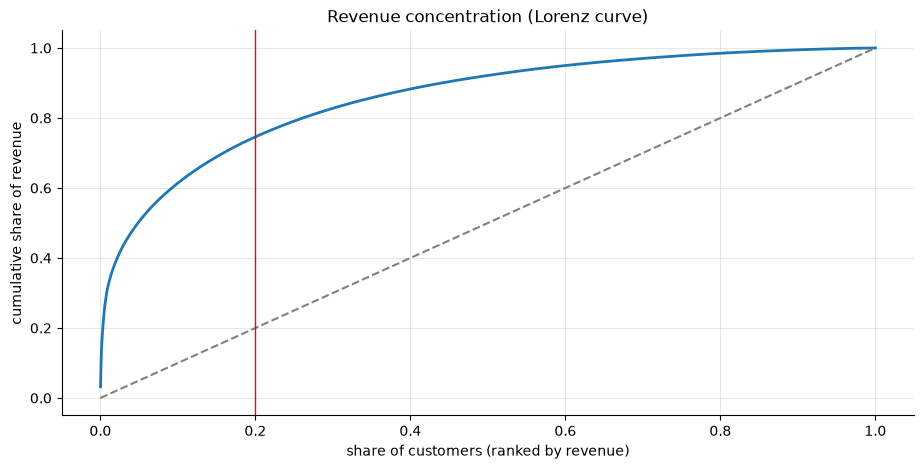

In [9]:
pareto = q('''
WITH c AS (SELECT CustomerID, SUM(revenue) AS rev FROM sales WHERE CustomerID IS NOT NULL GROUP BY CustomerID),
r AS (
  SELECT rev, ROW_NUMBER() OVER (ORDER BY rev DESC) AS rnk, COUNT(*) OVER () AS n,
         SUM(rev) OVER (ORDER BY rev DESC ROWS UNBOUNDED PRECEDING) AS cum_rev, SUM(rev) OVER () AS total
  FROM c
)
SELECT 1.0 * rnk / n AS customer_share, cum_rev / total AS revenue_share FROM r ORDER BY rnk
''')
top = {p: pareto.loc[pareto.customer_share <= p, "revenue_share"].max() for p in (0.01, 0.05, 0.20)}
print({f"top {int(k*100)}% customers": f"{v:.1%} of revenue" for k, v in top.items()})
ax = pareto.plot(x="customer_share", y="revenue_share", legend=False, lw=2)
ax.plot([0, 1], [0, 1], ls="--", c="grey"); ax.axvline(0.2, c="red", lw=1)
ax.set_xlabel("share of customers (ranked by revenue)"); ax.set_ylabel("cumulative share of revenue")
ax.set_title("Revenue concentration (Lorenz curve)"); plt.show()

## 7. Cohort retention

A customer's cohort is the month of their first purchase. Retention is the share of that cohort that buys again *k* months later.

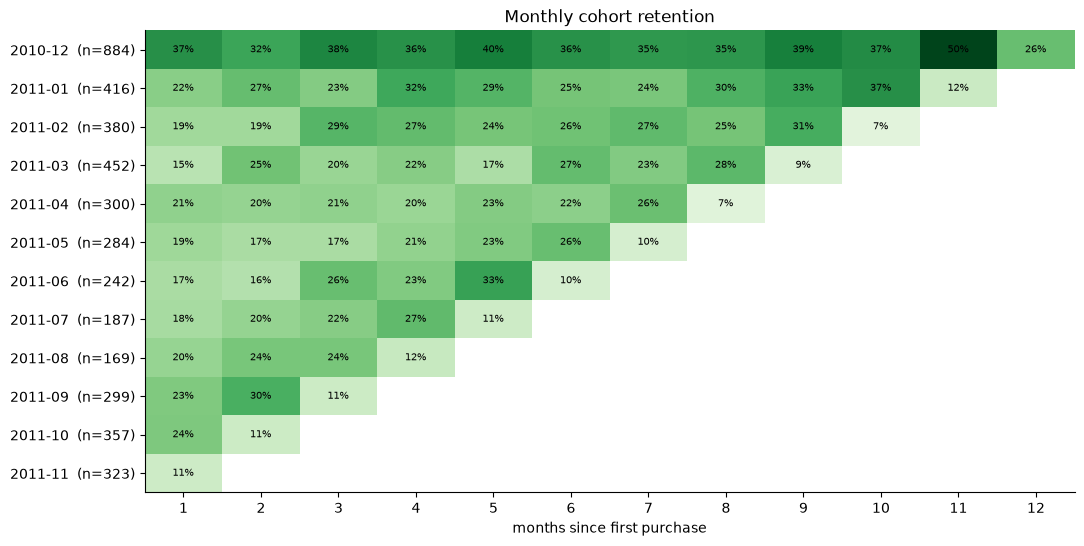

In [10]:
cohort = q('''
WITH first AS (SELECT CustomerID, MIN(month) AS cohort FROM sales WHERE CustomerID IS NOT NULL GROUP BY CustomerID),
act AS (
  SELECT DISTINCT s.CustomerID, f.cohort,
         (CAST(substr(s.month,1,4) AS INT) - CAST(substr(f.cohort,1,4) AS INT)) * 12
       + (CAST(substr(s.month,6,2) AS INT) - CAST(substr(f.cohort,6,2) AS INT)) AS k
  FROM sales s JOIN first f USING (CustomerID)
)
SELECT cohort, k, COUNT(*) AS active,
       1.0 * COUNT(*) / FIRST_VALUE(COUNT(*)) OVER (PARTITION BY cohort ORDER BY k) AS retention
FROM act GROUP BY cohort, k ORDER BY cohort, k
''')
ret = cohort.pivot(index="cohort", columns="k", values="retention").drop(index="2011-12", errors="ignore")
sizes = cohort[cohort.k == 0].set_index("cohort")["active"]
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(ret.iloc[:, 1:], cmap="Greens", vmin=0, vmax=0.5, aspect="auto")
for i in range(ret.shape[0]):
    for j in range(1, ret.shape[1]):
        v = ret.iloc[i, j]
        if pd.notna(v): ax.text(j - 1, i, f"{v:.0%}", ha="center", va="center", fontsize=7)
ax.set_yticks(range(len(ret)), [f"{c}  (n={sizes[c]})" for c in ret.index]); ax.set_xticks(range(ret.shape[1] - 1), ret.columns[1:])
ax.set_xlabel("months since first purchase"); ax.set_title("Monthly cohort retention"); ax.grid(False); plt.show()

In [11]:
q('''
WITH first AS (SELECT CustomerID, MIN(InvoiceDate) AS first_buy FROM sales WHERE CustomerID IS NOT NULL GROUP BY CustomerID),
orders AS (SELECT CustomerID, COUNT(DISTINCT InvoiceNo) AS n_orders FROM sales WHERE CustomerID IS NOT NULL GROUP BY CustomerID)
SELECT CASE WHEN f.first_buy < '2011-01-01' THEN 'Dec-2010 cohort' ELSE 'joined in 2011' END AS group_,
       COUNT(*) AS customers, ROUND(AVG(n_orders), 2) AS avg_orders,
       ROUND(100.0 * AVG(n_orders > 1), 1) AS pct_repeat_buyers
FROM first f JOIN orders o USING (CustomerID) GROUP BY group_
''')

,group_,customers,avg_orders,pct_repeat_buyers
0,Dec-2010 cohort,884,9.36,87.40
1,joined in 2011,3450,2.94,59.60


## 8. RFM segmentation

Each customer gets a 1–5 score (using `NTILE`) on three measures, scored as of the day after the last invoice:
- **R**ecency: days since their last order
- **F**requency: number of orders
- **M**onetary: total spend

The scores are then mapped to segments the marketing team can act on.

In [12]:
rfm = q('''
WITH ref AS (SELECT DATE(MAX(InvoiceDate), '+1 day') AS d FROM sales),
c AS (
  SELECT CustomerID,
         JULIANDAY((SELECT d FROM ref)) - JULIANDAY(MAX(InvoiceDate)) AS recency_days,
         COUNT(DISTINCT InvoiceNo) AS frequency, SUM(revenue) AS monetary
  FROM sales WHERE CustomerID IS NOT NULL GROUP BY CustomerID
),
s AS (
  SELECT *, NTILE(5) OVER (ORDER BY recency_days DESC) AS R,
            NTILE(5) OVER (ORDER BY frequency)        AS F,
            NTILE(5) OVER (ORDER BY monetary)         AS M
  FROM c
)
SELECT *, CASE
    WHEN R >= 4 AND F >= 4 AND M >= 4 THEN 'Champions'
    WHEN R >= 3 AND F >= 3              THEN 'Loyal'
    WHEN R >= 4 AND F <= 2              THEN 'New / promising'
    WHEN R <= 2 AND F >= 3              THEN 'At risk'
    WHEN R <= 2 AND F <= 2              THEN 'Lost / hibernating'
    ELSE 'Needs attention' END AS segment
FROM s
''')
seg = (rfm.groupby("segment")
          .agg(customers=("CustomerID", "size"), avg_recency_days=("recency_days", "mean"),
               avg_orders=("frequency", "mean"), revenue=("monetary", "sum"))
          .assign(pct_customers=lambda d: d.customers / d.customers.sum() * 100,
                  pct_revenue=lambda d: d.revenue / d.revenue.sum() * 100)
          .sort_values("revenue", ascending=False))
seg

,customers,avg_recency_days,avg_orders,revenue,pct_customers,pct_revenue
segment,,,,,,
Champions,994,12.69,10.70,"5,747,752.74",22.93,65.73
Loyal,952,34.70,3.76,"1,442,780.76",21.97,16.50
At risk,654,148.20,3.40,"871,028.53",15.09,9.96
Lost / hibernating,1080,218.27,1.10,"456,540.33",24.92,5.22
Needs attention,343,52.08,1.13,"132,884.96",7.91,1.52
New / promising,311,17.69,1.25,"92,926.32",7.18,1.06


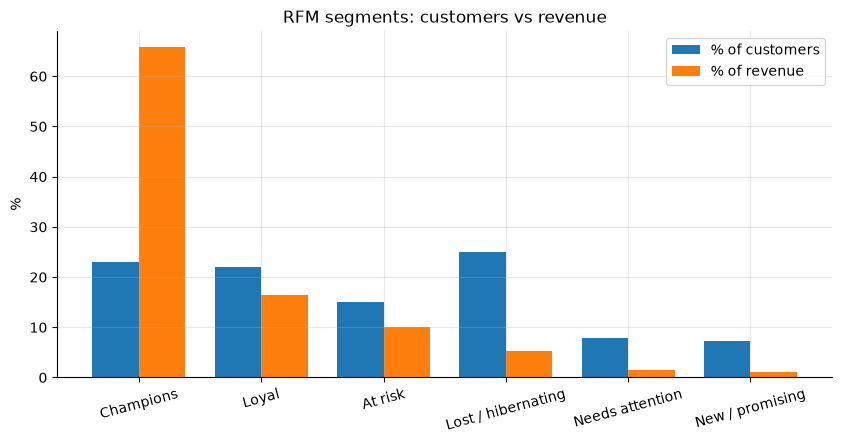

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(seg)); w = 0.38
ax.bar(x - w/2, seg.pct_customers, w, label="% of customers")
ax.bar(x + w/2, seg.pct_revenue, w, label="% of revenue")
ax.set_xticks(x, seg.index, rotation=15); ax.set_ylabel("%"); ax.set_title("RFM segments: customers vs revenue"); ax.legend(); plt.show()

## 9. Cancellations

In [14]:
q('''
SELECT ROUND((SELECT SUM(value) FROM cancels)) AS cancelled_value,
       ROUND((SELECT SUM(revenue) FROM sales))  AS gross_sales,
       ROUND(100.0 * (SELECT SUM(value) FROM cancels) / (SELECT SUM(revenue) FROM sales), 2) AS cancel_rate_pct,
       (SELECT COUNT(DISTINCT InvoiceNo) FROM cancels) AS cancelled_invoices
''')

,cancelled_value,gross_sales,cancel_rate_pct,cancelled_invoices
0,"478,789.00","10,254,959.00",4.67,3422


In [15]:
q('''
WITH s AS (SELECT Country, SUM(revenue) AS sales FROM sales GROUP BY Country),
c AS (SELECT Country, SUM(value) AS cancelled FROM cancels GROUP BY Country)
SELECT s.Country, ROUND(s.sales) AS sales, ROUND(COALESCE(c.cancelled, 0)) AS cancelled,
       ROUND(100.0 * COALESCE(c.cancelled, 0) / s.sales, 1) AS cancel_rate_pct
FROM s LEFT JOIN c USING (Country) WHERE s.sales > 50000 ORDER BY cancel_rate_pct DESC
''')

,Country,sales,cancelled,cancel_rate_pct
0,Spain,"55,707.00","3,960.00",7.10
1,United Kingdom,"8,726,607.00","445,843.00",5.10
2,EIRE,"276,091.00","11,566.00",4.20
3,Germany,"205,381.00","4,761.00",2.30
4,France,"184,679.00","2,419.00",1.30
5,Switzerland,"53,066.00",583.00,1.10
6,Australia,"138,104.00","1,181.00",0.90
7,Netherlands,"283,889.00",410.00,0.10


In [16]:
q('''
SELECT StockCode, MAX(Description) AS product, SUM(qty) AS units_cancelled, ROUND(SUM(value)) AS value_cancelled,
       COUNT(DISTINCT InvoiceNo) AS cancel_invoices
FROM cancels GROUP BY StockCode ORDER BY value_cancelled DESC LIMIT 8
''')

,StockCode,product,units_cancelled,value_cancelled,cancel_invoices
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,"168,470.00",1
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,74494,"77,480.00",10
2,22423,REGENCY CAKESTAND 3 TIER,857,"9,723.00",180
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2578,"6,624.00",42
4,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3150,"6,591.00",3
5,23113,PANTRY CHOPPING BOARD,946,"4,803.00",6
6,48185,DOORMAT FAIRY CAKE,674,"4,555.00",3
7,21175,GIN + TONIC DIET METAL SIGN,2030,"3,775.00",7


Two "top products" are really **order-entry errors**:
- *Paper Craft, Little Birdie*: one customer ordered 80,995 units, and the order was cancelled the same day.
- *Medium Ceramic Top Storage Jar*: an order of 74,215 units was also cancelled.

A gross-sales ranking therefore overstates both products. Ranking by **net** revenue (sales minus cancellations) fixes this.

In [17]:
q('''
WITH s AS (SELECT StockCode, MAX(Description) AS product, SUM(revenue) AS gross FROM sales GROUP BY StockCode),
c AS (SELECT StockCode, SUM(value) AS cancelled FROM cancels GROUP BY StockCode)
SELECT s.StockCode, s.product, ROUND(s.gross) AS gross, ROUND(COALESCE(c.cancelled, 0)) AS cancelled,
       ROUND(s.gross - COALESCE(c.cancelled, 0)) AS net_revenue
FROM s LEFT JOIN c USING (StockCode) ORDER BY net_revenue DESC LIMIT 10
''')

,StockCode,product,gross,cancelled,net_revenue
0,22423,REGENCY CAKESTAND 3 TIER,"174,157.00","9,723.00","164,434.00"
1,47566,PARTY BUNTING,"99,445.00","1,201.00","98,244.00"
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"104,463.00","6,624.00","97,838.00"
3,85099B,JUMBO BAG RED RETROSPOT,"94,160.00","1,984.00","92,176.00"
4,23084,RABBIT NIGHT LIGHT,"66,870.00",208.00,"66,662.00"
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"64,876.00","1,160.00","63,715.00"
6,84879,ASSORTED COLOUR BIRD ORNAMENT,"58,928.00",135.00,"58,792.00"
7,79321,CHILLI LIGHTS,"54,096.00",350.00,"53,747.00"
8,22502,PICNIC BASKET WICKER SMALL,"51,409.00",385.00,"51,024.00"
9,22197,SMALL POPCORN HOLDER,"51,334.00",367.00,"50,968.00"


In [18]:
q('''
WITH big AS (SELECT InvoiceNo FROM cancels GROUP BY InvoiceNo HAVING SUM(qty) >= 50000)
SELECT ROUND(100.0 * (SELECT SUM(value) FROM cancels WHERE InvoiceNo NOT IN big)
             / ((SELECT SUM(revenue) FROM sales) - (SELECT SUM(value) FROM cancels WHERE InvoiceNo IN big)), 2)
       AS cancel_rate_excl_two_errors_pct
''')

,cancel_rate_excl_two_errors_pct
0,2.33


## 10. Findings

1. **Data quality first.**
   - 25% of lines have no customer ID, 1.7% are cancellations, and about 5,400 lines are exact duplicates.
   - Two cancelled bulk orders (80,995 and 74,215 units, each reversed within about 20 minutes) are entry errors.
     Left in, they push two products into the top 6 and double the apparent cancellation rate (4.7% → **2.3%** without them).
     Any "top products" report built on gross sales would have been wrong.
2. **Revenue is seasonal and back-loaded.**
   - Monthly revenue sat around £0.5–0.75m until August.
   - It then climbed to **£1.45m in November**, about twice the spring level, as wholesale buyers stocked up for Christmas.
   - Average order value held steady at about £420–620. The growth came from **more orders and more customers**, not bigger baskets.
3. **One market, few customers.**
   - The UK is 85% of revenue.
   - The Netherlands, Ireland (EIRE) and Australia are each tiny in customer count (3–9 customers), but their average orders run £1,000–3,000.
     These are wholesale accounts worth managing one by one.
   - The **top 1% of customers bring 32% of revenue, and the top 20% bring 75%**.
4. **Retention is the growth lever.**
   - The first cohort (Dec 2010) is exceptional: 87% made a repeat purchase, and 32–40% are active every month.
   - Customers acquired in 2011 repeat far less (60% ever buy again; 15–24% are active in the following month).
   - Each cohort's final value is low only because December 2011 has just 9 days of data.
5. **RFM segments say where to spend effort.**
   - **Champions** are 23% of customers and 66% of revenue: protect them with account management and early access to the Christmas range.
   - **At-risk** customers (15%, average 148 days since their last order, about 10% of revenue) are the cheapest revenue to win back.
   - **Lost / hibernating** customers are 25% of the base but only 5% of revenue, so a low-cost reactivation campaign is enough for them.
6. **Operations: the shop runs Monday to Friday.**
   - No orders are placed on Saturday, and Sunday trade is light and starts later in the day.
   - Revenue peaks at 10:00–12:00 on Tuesday to Thursday. That is the window for promotions and for staffing customer service.